# CMP6202 – Notebook 04: Evaluation, improvements and conclusion

**Project:** Multi-class Classification for Cloud Network Intrusion Detection on AWS Using CSE-CIC-IDS2018

This notebook covers report sections **5** and **6**. It loads the searches fitted in notebook 03 and evaluates
them on the held-out test set for the first time.

**Order of decisions.** Everything that chooses something was fixed on the training set beforehand: the
hyper-parameters (cross-validation in notebook 03), the ablation results (cross-validation below) and the rule for
picking the final model, which I state before looking at any test score:

> *Final model = the highest cross-validated macro F1. Models within one standard deviation of the best are treated
> as tied, and a tie is broken by the lower inference time.*

The test set only reports how the already-chosen models perform.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
from IPython.display import display

from nids import config, data, evaluation, models, plotting

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 20)
plotting.apply_style()
warnings.filterwarnings("ignore", category=FutureWarning)


def save_text(name: str, text: str) -> None:
    # I save every copy-ready paragraph so the report quotes the code's numbers; line breaks inside a
    # paragraph are joined so the text pastes into Word cleanly.
    paragraphs = [" ".join(block.split()) for block in text.strip().split("\n\n")]
    clean = "\n\n".join(paragraphs)
    (config.TEXT_DIR / f"{name}.txt").write_text(clean + "\n")
    print(clean, f"\n\n[{len(clean.split())} words → reports/text/{name}.txt]")


sample = data.load_sample()
split = data.load_split(sample)
data.assert_no_leakage(split)
X_train, y_train, X_test, y_test = split.X_train, split.y_train, split.X_test, split.y_test
runs = {name: models.load_or_run_search(name, X_train, y_train,
                                        force=os.environ.get("NIDS_FORCE_RETRAIN") == "1")
        for name in models.MODEL_NAMES}
print(f"Test set: {len(X_test):,} flows {y_test.value_counts().to_dict()}")

Test set: 15,000 flows {'Benign': 12715, 'SSH-Bruteforce': 2276, 'FTP-BruteForce': 9}


# 5 Evaluation and further modelling improvements

### 5.1 Test-set results of the tuned models

,accuracy,f1_weighted,f1_macro,precision_macro,recall_macro,recall_ftp,f1_macro_ci_low,f1_macro_ci_high,inference_ms_per_1000
model,,,,,,,,,
Logistic Regression,0.99980,0.99981,0.96655,0.93925,0.99992,1.0,0.91659,1.0,1.19297
Decision Tree,0.99987,0.99987,0.99983,0.99983,0.99983,1.0,0.99957,1.0,0.51317
Random Forest,0.99993,0.99994,0.98244,0.96667,0.99997,1.0,0.95234,1.0,2.95501


precision  recall  f1-score  support
Logistic Regression Benign             1.0000  0.9998    0.9999  12715.0
                    FTP-BruteForce     0.8182  1.0000    0.9000      9.0
                    SSH-Bruteforce     0.9996  1.0000    0.9998   2276.0
Decision Tree       Benign             0.9999  0.9999    0.9999  12715.0
                    FTP-BruteForce     1.0000  1.0000    1.0000      9.0
                    SSH-Bruteforce     0.9996  0.9996    0.9996   2276.0
Random Forest       Benign             1.0000  0.9999    1.0000  12715.0
                    FTP-BruteForce     0.9000  1.0000    0.9474      9.0
                    SSH-Bruteforce     1.0000  1.0000    1.0000   2276.0

,model,true,predicted,flows
0,Logistic Regression,Benign,FTP-BruteForce,2
1,Logistic Regression,Benign,SSH-Bruteforce,1
7,Decision Tree,Benign,SSH-Bruteforce,1
10,Decision Tree,SSH-Bruteforce,Benign,1
12,Random Forest,Benign,FTP-BruteForce,1


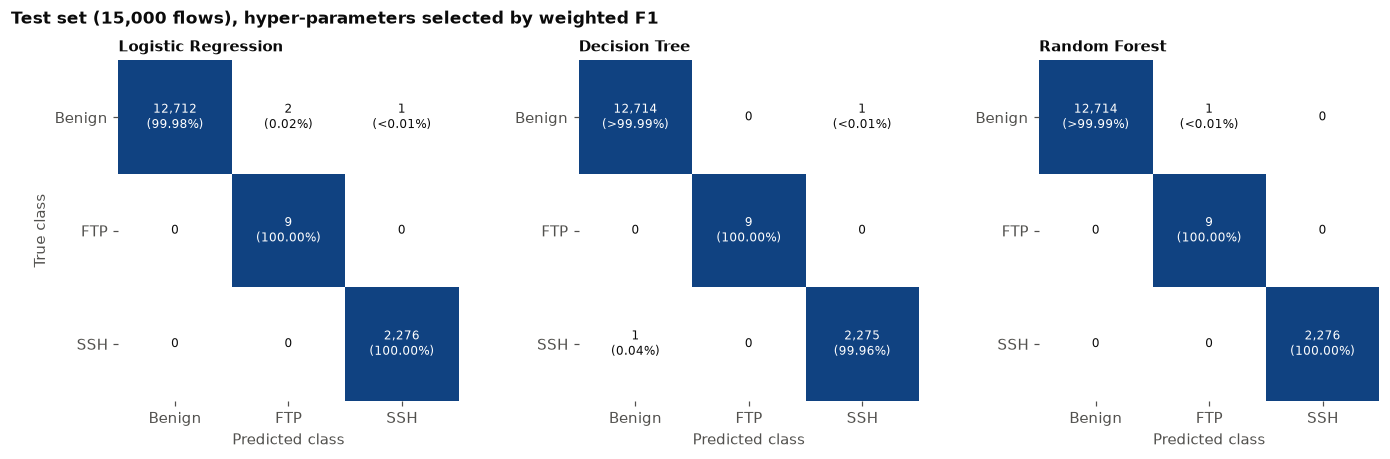

In [2]:
predictions, test_rows = {}, []
for name, run in runs.items():
    model = run.search.best_estimator_
    predictions[name] = model.predict(X_test)
    scores = evaluation.score_predictions(y_test, predictions[name])
    low, high = evaluation.bootstrap_interval(y_test, predictions[name], "f1_macro")
    test_rows.append({"model": name, **scores, "f1_macro_ci_low": low, "f1_macro_ci_high": high,
                      "inference_ms_per_1000": evaluation.inference_ms_per_1000(model, X_test)})
test_results = pd.DataFrame(test_rows).set_index("model")
display(test_results.round(5))
test_results.round(6).to_csv(config.TABLES_DIR / "5_1_test_results.csv")

per_class = pd.concat({name: evaluation.per_class_report(y_test, p) for name, p in predictions.items()})
display(per_class.round(4))
per_class.round(6).to_csv(config.TABLES_DIR / "5_1_test_per_class.csv")

fig = plotting.plot_confusion_matrices({n: (y_test.to_numpy(), p) for n, p in predictions.items()},
                                       "Test set (15,000 flows), hyper-parameters selected by weighted F1")
plotting.save_figure(fig, "5_1_confusion_matrices_test")

test_errors = pd.DataFrame([
    {"model": n, "true": t, "predicted": p, "flows": int(((y_test.to_numpy() == t) & (pred == p)).sum())}
    for n, pred in predictions.items() for t in plotting.CLASS_ORDER for p in plotting.CLASS_ORDER if t != p
]).query("flows > 0")
display(test_errors)

### 5.2 Cross-validation versus test

If the test scores fall inside the range that cross-validation predicted, the models generalise to unseen flows
rather than memorising the training set. I compare accuracy, weighted F1 and macro F1, each with its uncertainty:
± 1 standard deviation across folds for cross-validation and a 95% stratified bootstrap interval for the test set.

,model,metric,cv_mean,cv_std,test,test_low,test_high
0,Logistic Regression,accuracy,0.99985,0.00012,0.99980,0.99953,1.0
1,Logistic Regression,f1_weighted,0.99985,0.00012,0.99981,0.99956,1.0
2,Logistic Regression,f1_macro,0.97928,0.01325,0.96655,0.91659,1.0
3,Decision Tree,accuracy,0.99985,0.00014,0.99987,0.99967,1.0
4,Decision Tree,f1_weighted,0.99985,0.00014,0.99987,0.99967,1.0
5,Decision Tree,f1_macro,0.99030,0.01918,0.99983,0.99957,1.0
6,Random Forest,accuracy,0.99993,0.00008,0.99993,0.99980,1.0
7,Random Forest,f1_weighted,0.99993,0.00008,0.99994,0.99981,1.0
8,Random Forest,f1_macro,0.99549,0.00892,0.98244,0.95234,1.0


PosixPath('<project>/reports/figures/5_2_cv_vs_test.png')

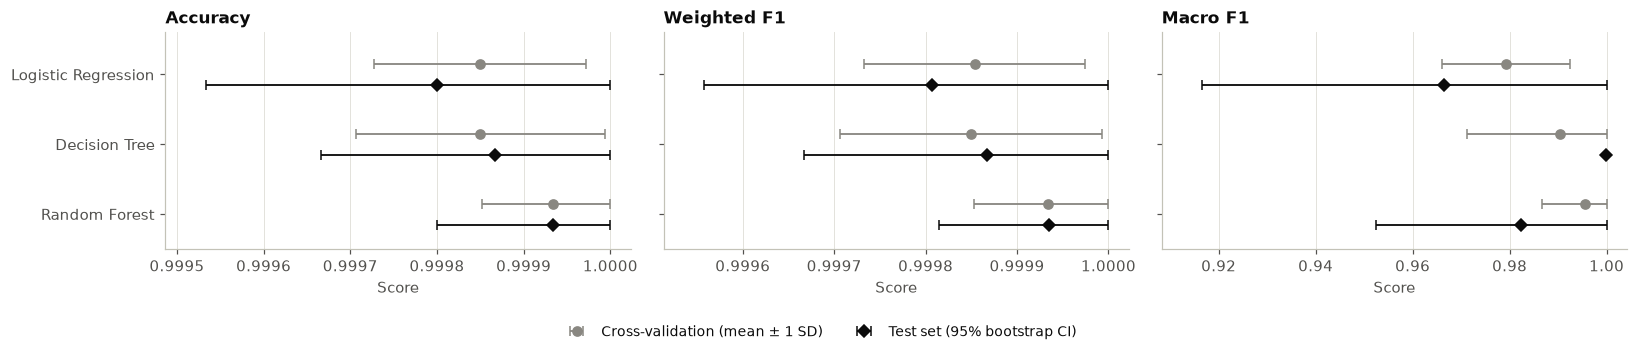

In [3]:
rows = []
for name, run in runs.items():
    res, best = run.search.cv_results_, run.search.best_index_
    for metric in ("accuracy", "f1_weighted", "f1_macro"):
        low, high = evaluation.bootstrap_interval(y_test, predictions[name], metric)
        rows.append({"model": name, "metric": metric,
                     "cv_mean": res[f"mean_test_{metric}"][best], "cv_std": res[f"std_test_{metric}"][best],
                     "test": test_results.loc[name, metric], "test_low": low, "test_high": high})
cv_vs_test = pd.DataFrame(rows)
display(cv_vs_test.round(5))
cv_vs_test.round(6).to_csv(config.TABLES_DIR / "5_2_cv_vs_test.csv", index=False)
fig = plotting.plot_cv_vs_test(cv_vs_test, {"accuracy": "Accuracy", "f1_weighted": "Weighted F1", "f1_macro": "Macro F1"})
plotting.save_figure(fig, "5_2_cv_vs_test")

### 5.3 Ablations: duplicates, shortcuts and resampling

Each ablation changes exactly one thing in the tuned pipeline and is scored with the same 5-fold cross-validation on
the training set, so the test set plays no part in these comparisons.

**(a) What a naive pipeline would report.** I repeat sampling and splitting *without* de-duplication and measure how
many test flows already occur, identically, in the training set.

In [4]:
cleaned_rows = data.build_cleaned_rows()
naive_sample = data.stratified_sample(cleaned_rows, floor=0)   # floor 0 = purely proportional
naive_split = data.split_sample(naive_sample)
overlap = data.train_test_overlap(naive_split)
naive_model, _ = evaluation.variant_pipeline(runs[models.FOREST], naive_split.X_train, "no_resampling")
naive_model, _ = evaluation.fit_timed(naive_model, naive_split.X_train, naive_split.y_train)
naive_scores = evaluation.score_predictions(naive_split.y_test, naive_model.predict(naive_split.X_test))
naive_table = pd.DataFrame({
    "naive test flows": naive_split.y_test.value_counts(),
    "share already in training set": overlap,
})
display(naive_table.round(4))
print("Overall share of naive test flows already seen in training:",
      f"{data.flow_hash(naive_split.X_test).isin(set(data.flow_hash(naive_split.X_train))).mean():.2%}")
print("Random Forest on the naive split:", {k: round(v, 5) for k, v in naive_scores.items()})
naive_table.round(6).to_csv(config.TABLES_DIR / "5_3_naive_overlap.csv")
del cleaned_rows

,naive test flows,share already in training set
Benign,9531,0.1236
FTP-BruteForce,2776,0.9996
SSH-Bruteforce,2693,0.5095


Overall share of naive test flows already seen in training: 35.50%
Random Forest on the naive split: {'accuracy': 1.0, 'f1_weighted': 1.0, 'f1_macro': 1.0, 'precision_macro': 1.0, 'recall_macro': 1.0, 'recall_ftp': 1.0}


**(b)–(d) Shortcut features and class-imbalance handling.**

model,Decision Tree,Logistic Regression,Random Forest
variant,,,
main,0.9903,0.9793,0.9955
with_dst_port,0.9960,0.9916,0.9999
no_window_sizes,0.9902,0.9793,0.9904
no_host_fingerprint,0.9903,0.9317,0.9387
class_weight,0.9953,0.9673,0.9955
no_resampling,0.9954,0.9837,0.9955


model,Decision Tree,Logistic Regression,Random Forest
variant,,,
main,0.9903,0.9620,0.9916
with_dst_port,0.9925,0.9843,1.0000
no_window_sizes,0.9902,0.9620,0.9916
no_host_fingerprint,0.9903,0.8904,0.9177
class_weight,0.9915,0.9416,0.9916
no_resampling,0.9915,0.9703,0.9916


PosixPath('<project>/reports/figures/5_3_ablation_cv_macro_f1.png')

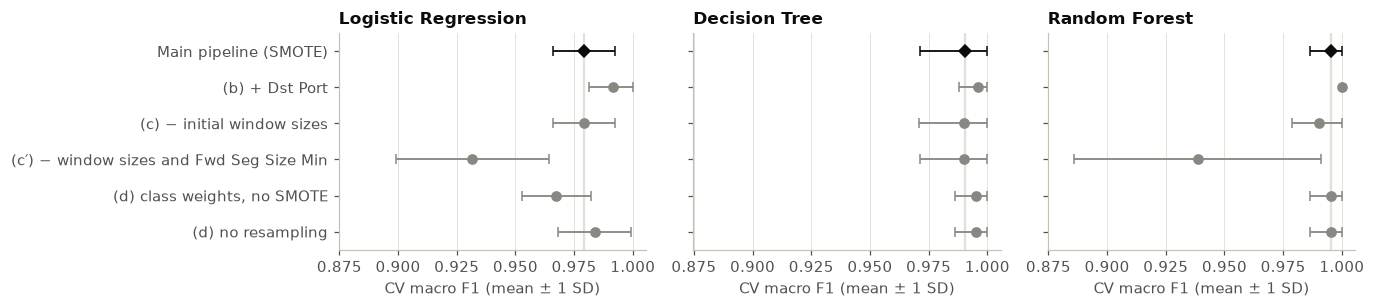

In [5]:
variant_labels = {
    "main": "Main pipeline (SMOTE)",
    "with_dst_port": "(b) + Dst Port",
    "no_window_sizes": "(c) − initial window sizes",
    "no_host_fingerprint": "(c′) − window sizes and Fwd Seg Size Min",
    "class_weight": "(d) class weights, no SMOTE",
    "no_resampling": "(d) no resampling",
}
ablation_rows = []
for name, run in runs.items():
    for variant in variant_labels:
        pipeline, X_variant = evaluation.variant_pipeline(run, X_train, variant)
        ablation_rows.append({"model": name, "variant": variant, **evaluation.cross_validated(pipeline, X_variant, y_train)})
ablation = pd.DataFrame(ablation_rows)
ablation.round(6).to_csv(config.TABLES_DIR / "5_3_ablation_cv.csv", index=False)
display(ablation.pivot(index="variant", columns="model", values="f1_macro_mean").reindex(variant_labels).round(4))
display(ablation.pivot(index="variant", columns="model", values="precision_macro_mean").reindex(variant_labels).round(4))
fig = plotting.plot_ablation(ablation, variant_labels)
plotting.save_figure(fig, "5_3_ablation_cv_macro_f1")

### 5.4 Improvement: selecting hyper-parameters by macro F1

Notebook 03 showed that weighted F1 is saturated (many settings within one standard deviation of the best), so tuning
against it picks almost arbitrarily. The search already scored every setting on macro F1, so selecting by macro F1
needs no new search: I take the setting with the highest cross-validated macro F1 and refit it on the training set.

In [6]:
macro_rows, macro_predictions, macro_models = [], {}, {}
for name, run in runs.items():
    pipeline, params, index = evaluation.selected_pipeline(run, "f1_macro")
    model, fit_seconds = evaluation.fit_timed(pipeline, X_train, y_train)
    macro_models[name] = model
    macro_predictions[name] = model.predict(X_test)
    res = run.search.cv_results_
    low, high = evaluation.bootstrap_interval(y_test, macro_predictions[name], "f1_macro")
    macro_rows.append({
        "model": name,
        "same setting as weighted F1": index == run.search.best_index_,
        "cv_f1_macro (weighted-selected)": res["mean_test_f1_macro"][run.search.best_index_],
        "cv_f1_macro (macro-selected)": res["mean_test_f1_macro"][index],
        "cv_f1_macro_std": res["std_test_f1_macro"][index],
        "test_f1_macro": evaluation.score_predictions(y_test, macro_predictions[name])["f1_macro"],
        "test_ci_low": low, "test_ci_high": high,
        "test_accuracy": evaluation.score_predictions(y_test, macro_predictions[name])["accuracy"],
        "test_recall_ftp": evaluation.score_predictions(y_test, macro_predictions[name])["recall_ftp"],
        "fit_seconds": fit_seconds,
        "inference_ms_per_1000": evaluation.inference_ms_per_1000(model, X_test),
    })
macro_selection = pd.DataFrame(macro_rows).set_index("model")
display(macro_selection.round(5))
macro_selection.round(6).to_csv(config.TABLES_DIR / "5_4_macro_selection.csv")

,same setting as weighted F1,cv_f1_macro (weighted-selected),cv_f1_macro (macro-selected),cv_f1_macro_std,test_f1_macro,test_ci_low,test_ci_high,test_accuracy,test_recall_ftp,fit_seconds,inference_ms_per_1000
model,,,,,,,,,,,
Logistic Regression,False,0.97928,0.98368,0.01551,0.98236,0.95200,1.0,0.99987,1.0,0.68744,1.22270
Decision Tree,False,0.99030,0.99534,0.00890,0.99991,0.99974,1.0,0.99993,1.0,0.45194,0.58458
Random Forest,True,0.99549,0.99549,0.00892,0.98244,0.95234,1.0,0.99993,1.0,3.79670,3.12156


### 5.5 Comparative analysis and choice of final model

I apply the rule stated at the top of the notebook to the macro-selected models (their cross-validated macro F1 is
the quantity the rule ranks on).

,CV macro F1,Test accuracy,Test macro F1 [95% CI],Test FTP recall,Training time (s),"Inference (ms / 1,000 flows)"
model,,,,,,
Logistic Regression,0.9837 ± 0.0155,0.99987,"0.9824 [0.9520, 1.0000]",1.0,0.69,1.22
Decision Tree,0.9953 ± 0.0089,0.99993,"0.9999 [0.9997, 1.0000]",1.0,0.45,0.58
Random Forest,0.9955 ± 0.0089,0.99993,"0.9824 [0.9523, 1.0000]",1.0,3.80,3.12


Highest CV macro F1: Random Forest; tied within 1 SD: ['Decision Tree', 'Random Forest']; final model (fastest of the tied): Decision Tree


PosixPath('<project>/reports/figures/5_5_confusion_matrices_test_macro_selected.png')

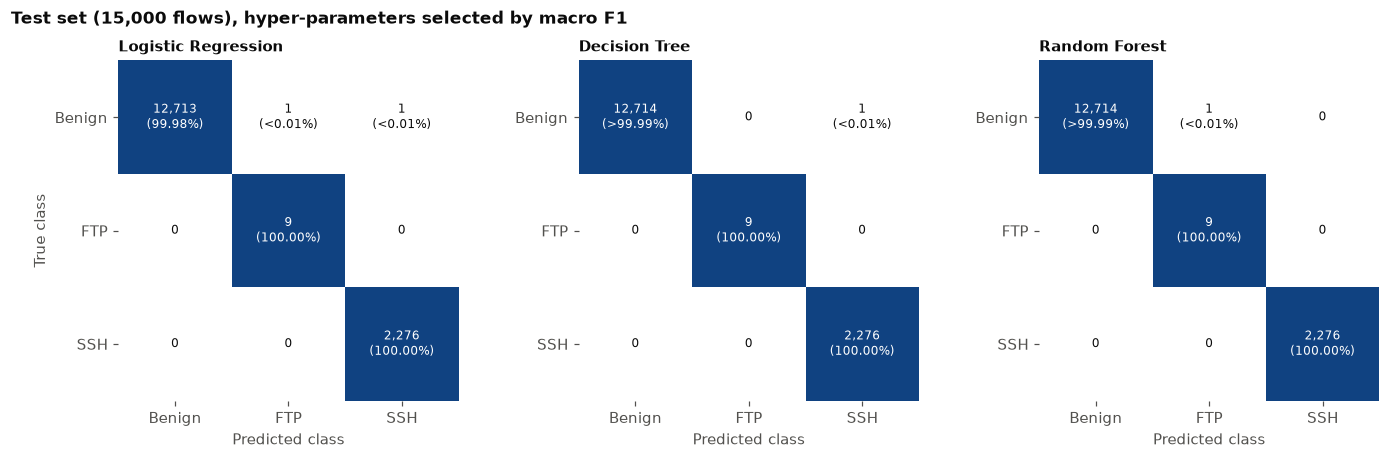

In [7]:
cv_best = macro_selection["cv_f1_macro (macro-selected)"]
leader = cv_best.idxmax()
tied = cv_best[cv_best >= cv_best[leader] - macro_selection.loc[leader, "cv_f1_macro_std"]].index.tolist()
final_name = macro_selection.loc[tied, "inference_ms_per_1000"].idxmin()

comparison = pd.DataFrame({
    "CV macro F1": cv_best.round(4).astype(str) + " ± " + macro_selection["cv_f1_macro_std"].round(4).astype(str),
    "Test accuracy": macro_selection["test_accuracy"].round(5),
    "Test macro F1 [95% CI]": macro_selection["test_f1_macro"].round(4).astype(str) + " [" +
                              macro_selection["test_ci_low"].map("{:.4f}".format) + ", " +
                              macro_selection["test_ci_high"].map("{:.4f}".format) + "]",
    "Test FTP recall": macro_selection["test_recall_ftp"],
    "Training time (s)": macro_selection["fit_seconds"].round(2),
    "Inference (ms / 1,000 flows)": macro_selection["inference_ms_per_1000"].round(2),
})
display(comparison)
comparison.to_csv(config.TABLES_DIR / "5_5_final_comparison.csv")
print(f"Highest CV macro F1: {leader}; tied within 1 SD: {tied}; final model (fastest of the tied): {final_name}")

fig = plotting.plot_confusion_matrices({n: (y_test.to_numpy(), p) for n, p in macro_predictions.items()},
                                       "Test set (15,000 flows), hyper-parameters selected by macro F1")
plotting.save_figure(fig, "5_5_confusion_matrices_test_macro_selected")

### 5.6 What the models learned

The Decision Tree can be read directly; for the Random Forest I report impurity importance (from training) and
permutation importance on the test set (the drop in macro F1 when one column is shuffled). Both under-rate features
that have a near-copy, because the model can fall back on the copy.

Decision Tree: depth 6, 10 leaves
if Fwd Seg Size Min <= 30.00:
|   → Benign
else (Fwd Seg Size Min > 30.00):
|   if Bwd Pkt Len Max <= 808.00:
|   |   if Bwd Pkts/s <= 14,693.26:
|   |   |   if Flow Pkts/s <= 8,903.76:
|   |   |   |   → Benign (subtree truncated)
|   |   |   else (Flow Pkts/s > 8,903.76):
|   |   |   |   → SSH-Bruteforce (subtree truncated)
|   |   else (Bwd Pkts/s > 14,693.26):
|   |   |   if Init Fwd Win Byts <= 17,537.50:
|   |   |   |   → Benign (subtree truncated)
|   |   |   else (Init Fwd Win Byts > 17,537.50):
|   |   |   |   → FTP-BruteForce
|   else (Bwd Pkt Len Max > 808.00):
|   |   → SSH-Bruteforce


,min,50%,max
Label,,,
Benign,0.0,20.0,40.0
FTP-BruteForce,40.0,40.0,40.0
SSH-Bruteforce,32.0,32.0,32.0


,impurity_importance,permutation_drop_f1_macro,permutation_std
Fwd Seg Size Min,0.1281,0.0110,0.0108
Init Fwd Win Byts,0.0756,0.0000,0.0000
Fwd Header Len,0.0718,-0.0035,0.0070
TotLen Fwd Pkts,0.0658,-0.0070,0.0086
Bwd Header Len,0.0656,0.0001,0.0000
Fwd Act Data Pkts,0.0656,0.0000,0.0000
Subflow Fwd Pkts,0.0597,-0.0140,0.0070
Tot Fwd Pkts,0.0515,0.0000,0.0000
Subflow Bwd Pkts,0.0441,0.0000,0.0000
Subflow Fwd Byts,0.0391,0.0000,0.0000


Root split of the Decision Tree: Fwd Seg Size Min


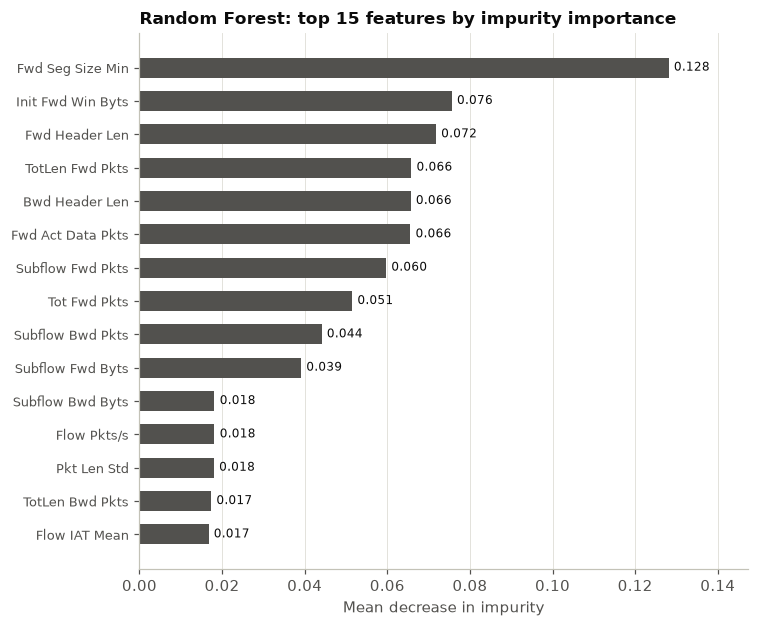

In [8]:
tree_model = macro_models[models.TREE]
tree = tree_model.named_steps["model"]
feature_names = list(tree_model.named_steps["preprocess"].get_feature_names_out())
print(f"Decision Tree: depth {tree.get_depth()}, {tree.get_n_leaves()} leaves")
# The tree splits standardised inputs; I convert its thresholds back to raw units so they can be read.
tree_rules = evaluation.tree_rules_in_original_units(tree_model, max_depth=4)
print(tree_rules)
(config.TABLES_DIR / "5_6_decision_tree_rules.txt").write_text(tree_rules + "\n")
seg_min = X_train.groupby(y_train, observed=True)["Fwd Seg Size Min"].describe()[["min", "50%", "max"]]
display(seg_min)

forest_model = macro_models[models.FOREST]
importance = evaluation.importance_table(forest_model, X_test, y_test, top=15)
display(importance.round(4))
importance.round(6).to_csv(config.TABLES_DIR / "5_6_random_forest_importance.csv")
fig = plotting.plot_importance(importance["impurity_importance"], "Random Forest: top 15 features by impurity importance",
                               "Mean decrease in impurity")
plotting.save_figure(fig, "5_6_random_forest_importance")
top_tree_split = tree.tree_.feature[0]
print("Root split of the Decision Tree:", feature_names[top_tree_split])

In [9]:
r = test_results
ab = ablation.set_index(["model", "variant"])["f1_macro_mean"]
ms = macro_selection
def delta(model, variant):
    return ab[(model, variant)] - ab[(model, "main")]

# I let the code decide which qualitative statements are true, so the text cannot contradict the tables.
macro_cmp = cv_vs_test[cv_vs_test["metric"] == "f1_macro"].set_index("model")
inside_1sd = (macro_cmp["test"] >= macro_cmp["cv_mean"] - macro_cmp["cv_std"]).to_dict()
overlaps = (macro_cmp["test_high"] >= macro_cmp["cv_mean"] - macro_cmp["cv_std"]).all()
below = [m for m, ok in inside_1sd.items() if not ok]
generalisation = (
    "Every test score falls within one standard deviation of its cross-validated mean"
    if not below else
    f"The point estimate falls below one standard deviation of the cross-validated mean for {', '.join(below)}, "
    + ("yet every 95% bootstrap interval overlaps the cross-validated range" if overlaps else "and not every interval overlaps it")
)
std_ab = ablation.set_index(["model", "variant"])["f1_macro_std"]
window_within_sd = all(abs(delta(m, "no_window_sizes")) <= std_ab[(m, "main")] for m in models.MODEL_NAMES)
cw_vs_none = {m: ab[(m, "class_weight")] - ab[(m, "no_resampling")] for m in models.MODEL_NAMES}
fp_drop = {m: -delta(m, "no_host_fingerprint") for m in models.MODEL_NAMES}
n_err_w = {m: int((predictions[m] != y_test.to_numpy()).sum()) for m in models.MODEL_NAMES}
n_err_m = {m: int((macro_predictions[m] != y_test.to_numpy()).sum()) for m in models.MODEL_NAMES}
fp_within_sd = all(abs(delta(m, "no_host_fingerprint")) <= std_ab[(m, "main")] for m in models.MODEL_NAMES)
fingerprint_phrase = (
    ", each within one standard deviation, so the remaining payload, size and timing features still separate the classes"
    if fp_within_sd else
    f"; the largest drop ({max(fp_drop, key=fp_drop.get)}, {max(fp_drop.values()):.4f}) shows that part of the performance rests on these host-specific values"
)

save_text("5_evaluation", f'''
Test set. All three tuned models detect every FTP-BruteForce flow in the test set (9 of 9) and misclassify between
{int(test_errors.groupby("model")["flows"].sum().min())} and {int(test_errors.groupby("model")["flows"].sum().max())} of 15,000 flows
(accuracy {r["accuracy"].min():.4f}–{r["accuracy"].max():.4f}; Figure 5.1). The test scores are consistent with
cross-validation for accuracy and weighted F1 (Figure 5.2). For macro F1, test scores range from
{r["f1_macro"].min():.4f} to {r["f1_macro"].max():.4f}. {generalisation}: Logistic Regression
[{r.loc["Logistic Regression", "f1_macro_ci_low"]:.4f}, {r.loc["Logistic Regression", "f1_macro_ci_high"]:.4f}], Decision Tree
[{r.loc["Decision Tree", "f1_macro_ci_low"]:.4f}, {r.loc["Decision Tree", "f1_macro_ci_high"]:.4f}], Random Forest
[{r.loc["Random Forest", "f1_macro_ci_low"]:.4f}, {r.loc["Random Forest", "f1_macro_ci_high"]:.4f}]. With nine FTP flows, one false
alarm lowers FTP precision to 0.90 and macro F1 by about 0.02, so the test set cannot rank the models; a model with no FTP
error also gets an artificially narrow interval, because no resample can contain an FTP error.

Ablations (Figure 5.3). (a) Without de-duplication, {overlap.get("FTP-BruteForce", float("nan")):.2%} of FTP-BruteForce and
{overlap.get("SSH-Bruteforce", float("nan")):.1%} of SSH-Bruteforce test flows already occur identically in the training set, and the Random
Forest scores a perfect {naive_scores["f1_macro"]:.4f} macro F1 on that split: a naive evaluation largely measures recall of memorised rows. (b) Adding Dst Port raises cross-validated macro F1 for every model
(Random Forest {delta(models.FOREST, "with_dst_port"):+.4f}, Logistic Regression {delta(models.LOGREG, "with_dst_port"):+.4f}), confirming that
the port is a shortcut. (c) Removing the initial window sizes changes macro F1 by {delta(models.LOGREG, "no_window_sizes"):+.4f},
{delta(models.TREE, "no_window_sizes"):+.4f} and {delta(models.FOREST, "no_window_sizes"):+.4f} (LR, DT, RF){", each within one standard deviation" if window_within_sd else ""},
so the models {"do not depend on" if window_within_sd else "partly depend on"} the window size alone. The reason is visible in the tree's root
split, Fwd Seg Size Min ≤ 30 bytes: this value is constant within each attack (40 for every FTP flow, 32 for every SSH flow) and
plausibly also reflects the attacking host's TCP configuration. (c′) Removing it together with the window sizes changes macro F1 by
{delta(models.LOGREG, "no_host_fingerprint"):+.4f}, {delta(models.TREE, "no_host_fingerprint"):+.4f} and {delta(models.FOREST, "no_host_fingerprint"):+.4f} (LR, DT, RF){fingerprint_phrase}. (d) SMOTE did not help: without any resampling
macro F1 is {delta(models.LOGREG, "no_resampling"):+.4f}, {delta(models.TREE, "no_resampling"):+.4f} and {delta(models.FOREST, "no_resampling"):+.4f}
relative to SMOTE, and class weights do {"no better than" if max(cw_vs_none.values()) <= 0.0005 else "better than"} no resampling. FTP-BruteForce is already perfectly separable, so synthetic FTP flows
only add false alarms.

Improvement and model choice. I re-selected hyper-parameters by macro F1 instead of the saturated weighted F1. Its
cross-validated macro F1 is optimistic by construction (it is the best of 20 settings), so the fair evidence is the test set,
where macro F1 rose from {r.loc["Logistic Regression", "f1_macro"]:.4f} to {ms.loc["Logistic Regression", "test_f1_macro"]:.4f} for Logistic
Regression and from {r.loc["Decision Tree", "f1_macro"]:.4f} to {ms.loc["Decision Tree", "test_f1_macro"]:.4f} for the Decision Tree
({n_err_w[models.LOGREG]} → {n_err_m[models.LOGREG]} and {n_err_w[models.TREE]} → {n_err_m[models.TREE]} misclassified test flows); for the
Random Forest both metrics select the same setting. Applying the
rule fixed in advance, {leader} has the highest cross-validated macro F1, {", ".join(t for t in tied if t != leader) or "no other model"}
{"is" if len(tied) == 2 else "are"} within one standard deviation, and {final_name} is the fastest of the tied models
({ms.loc[final_name, "inference_ms_per_1000"]:.2f} ms per 1,000 flows against {ms.loc[leader, "inference_ms_per_1000"]:.2f} ms), so I select
the {final_name} (test macro F1 {ms.loc[final_name, "test_f1_macro"]:.4f}, FTP recall {ms.loc[final_name, "test_recall_ftp"]:.2f}).
Logistic Regression was selected with the symlog transform in both searches, and the single tree is the cheapest model
to run and can be read as threshold rules (depth {tree.get_depth()}, {tree.get_n_leaves()} leaves).
''')

Test set. All three tuned models detect every FTP-BruteForce flow in the test set (9 of 9) and misclassify between 1 and 3 of 15,000 flows (accuracy 0.9998–0.9999; Figure 5.1). The test scores are consistent with cross-validation for accuracy and weighted F1 (Figure 5.2). For macro F1, test scores range from 0.9666 to 0.9998. The point estimate falls below one standard deviation of the cross-validated mean for Random Forest, yet every 95% bootstrap interval overlaps the cross-validated range: Logistic Regression [0.9166, 1.0000], Decision Tree [0.9996, 1.0000], Random Forest [0.9523, 1.0000]. With nine FTP flows, one false alarm lowers FTP precision to 0.90 and macro F1 by about 0.02, so the test set cannot rank the models; a model with no FTP error also gets an artificially narrow interval, because no resample can contain an FTP error.

Ablations (Figure 5.3). (a) Without de-duplication, 99.96% of FTP-BruteForce and 50.9% of SSH-Bruteforce test flows already occur identically in the t

# 6 Conclusion

## 6.1 Summary of results

In [10]:
fp = {m: ablation.set_index(["model", "variant"]).loc[(m, "no_host_fingerprint"), "f1_macro_mean"]
         - ablation.set_index(["model", "variant"]).loc[(m, "main"), "f1_macro_mean"] for m in models.MODEL_NAMES}
reliant = [m for m, d in fp.items() if d < -0.01]
robust = [m for m in models.MODEL_NAMES if m not in reliant]
rq2_host = (
    f"{' and '.join(reliant)} also lean on attacker-specific TCP values (macro F1 falls by up to {-min(fp.values()):.3f} "
    f"without them), while {' and '.join(robust) or 'no model'} does not"
    if reliant else "no model depends on the attacker-specific TCP values"
)
save_text("6_1_summary", f'''
I built a reproducible pipeline that classifies network flows from one day of CSE-CIC-IDS2018 as Benign,
FTP-BruteForce or SSH-Bruteforce. The most consequential step was data preparation: 99.98% of FTP-BruteForce rows were exact
repeats, and the destination port and timestamp encode how the labels were made; without de-duplication
{overlap["FTP-BruteForce"]:.2%} of FTP-BruteForce test flows would have been exact copies of training flows. On the cleaned data all three algorithms detect both attacks almost perfectly: the
selected {final_name} detects all 9 FTP-BruteForce test flows with test accuracy {ms.loc[final_name, "test_accuracy"]:.4f}, trains
in {ms.loc[final_name, "fit_seconds"]:.2f} s on 60,000 flows and classifies 1,000 flows in {ms.loc[final_name, "inference_ms_per_1000"]:.2f} ms.
For the three research questions: (RQ1) flow statistics alone separate these brute-force attacks from benign traffic,
with at most {int(test_errors.groupby("model")["flows"].sum().max())} errors in 15,000 test flows; (RQ2) every model gains from the
destination-port shortcut, and {rq2_host}; (RQ3) SMOTE brought no benefit, because
the minority class was already separable. Because the differences between models amount to one or two flows, the choice
should rest on cost and interpretability rather than on accuracy.

Recommended next steps for a security engineering lead: (1) treat these scores as an upper bound, since the data covers
one day and two attacks, each launched from one Kali Linux machine; (2) before deployment, validate on other CSE-CIC-IDS2018 days and on
locally captured traffic, using a time-based split; (3) deploy the {final_name} as a lightweight first-line filter in
front of existing signature-based detection, retraining when new attack types are labelled; (4) monitor the false-alarm
rate, the error that dominated here.
''')

I built a reproducible pipeline that classifies network flows from one day of CSE-CIC-IDS2018 as Benign, FTP-BruteForce or SSH-Bruteforce. The most consequential step was data preparation: 99.98% of FTP-BruteForce rows were exact repeats, and the destination port and timestamp encode how the labels were made; without de-duplication 99.96% of FTP-BruteForce test flows would have been exact copies of training flows. On the cleaned data all three algorithms detect both attacks almost perfectly: the selected Decision Tree detects all 9 FTP-BruteForce test flows with test accuracy 0.9999, trains in 0.45 s on 60,000 flows and classifies 1,000 flows in 0.58 ms. For the three research questions: (RQ1) flow statistics alone separate these brute-force attacks from benign traffic, with at most 3 errors in 15,000 test flows; (RQ2) every model gains from the destination-port shortcut, and Logistic Regression and Random Forest also lean on attacker-specific TCP values (macro F1 falls by up to 0.057 

## 6.2 Reflection on Individual Learning

*This section must be written by me in my own words. The prompts and facts below are reminders of what happened during
the project; they are not text for the report.*

**Technical challenges to reflect on (with evidence in the notebooks):**

* The raw file looked balanced, but 99.98% of FTP rows were repeats; finding this needed hashing about one million rows
  (notebook 01). What did this teach me about trusting public datasets?
* Destination port and timestamp were part of the labelling procedure; the Timestamp column also used a 12-hour clock
  without AM/PM (notebook 01, section 1.1).
* Weighted F1 was saturated and could not rank models; I switched the selection metric to macro F1 (notebooks 03–04).
* SMOTE, which I expected to help, did not; the ablation showed why (notebook 04, section 5.3).
* Only nine FTP flows in the test set: bootstrap intervals showed that differences of one flow are not meaningful.
* Practical issues: library API changes (scikit-learn 1.8 deprecated `penalty`), runtime of the search on 10 cores,
  caching fitted searches, making results byte-for-byte reproducible.

**Certification evidence (placeholders – insert screenshots or Credly links):**

* *AWS Cloud Quest: Security* (Training Badge, issued 4 October 2026) – [how the security concepts informed this
  project, e.g. network monitoring and VPC traffic on AWS] – evidence: [Credly link / screenshot]
* *AWS Cloud Quest: Solutions Architect* (Training Badge, issued 9 October 2026) – [how architectural thinking informs
  deploying this detector on AWS, e.g. cost of inference, where the model would run] – evidence: [Credly link / screenshot]
* *AWS Cloud Quest: Machine Learning* (planned during the project) – [link to model building and evaluation in this
  project] – evidence: [Credly link / screenshot]
* [Fourth AI/ML certification, if obtained] – evidence: [link]